In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import transforms

from torch.utils.data import Dataset, DataLoader

import os

from tqdm.auto import tqdm

import math

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Checking device

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Colab Server Setup

In [4]:
# Downloading Image-Caption-pair csv file from my github repo to the Colab server's disk/memory

import urllib.request

#url = f"https://raw.githubusercontent.com/Divyanshu1331/generative-models-lab/blob/main/07-clip/Dataset/ImagePath_caption_colab.csv.gz"
url = "https://raw.githubusercontent.com/Divyanshu1331/generative-models-lab/main/07-clip/Dataset/ImagePath_caption_colab.csv.gz"

data_path_on_server = "/content/data"
os.makedirs(data_path_on_server, exist_ok = True)

csv_file_path = os.path.join(data_path_on_server, os.path.basename(url))


if os.path.exists(csv_file_path) == False:                         # If the csv file is already downloaded then skip downloading

    urllib.request.urlretrieve(url, csv_file_path)                 # Downloads file directly from Internet(url) and saves in the respective environment


print(f"Size of the CSV file downloaded: {os.path.getsize(csv_file_path) / 1e6:.1f} MB")

Size of the CSV file downloaded: 11.5 MB


In [6]:
# Viewing the Image-caption-pair csv file downloded on Colab's server 

train_data = pd.read_csv("/content/data/ImagePath_caption_colab.csv.gz")

print(train_data.shape)
train_data.head()

(591753, 2)


,Img_Path,Caption
0,/content/train2017/000000203564.jpg,A bicycle replica with a clock as the front wh...
1,/content/train2017/000000322141.jpg,A room with blue walls and a white sink and door.
2,/content/train2017/000000016977.jpg,A car that seems to be parked illegally behind...
3,/content/train2017/000000106140.jpg,A large passenger airplane flying through the ...
4,/content/train2017/000000106140.jpg,There is a GOL plane taking off in a partly cl...


In [7]:
# Downloading the COCO train images on the COlab's disk

import zipfile, subprocess, requests

URL      = "http://images.cocodataset.org/zips/train2017.zip"      # URL containing zip file of COCO2017's train images

ZIP_PATH = "/content/train2017.zip"                                # Path on Colab's disk to store COCO's training images in zip file
IMG_DIR  = "/content/train2017"                                    # Path on Colab's disk to store unziped file

EXPECTED = 118287                                                  # number of images in COCO train2017


def count_images():                                                # Count of images in the Colab's image directory

    return len(os.listdir(IMG_DIR)) if os.path.isdir(IMG_DIR) else 0



if count_images() >= EXPECTED:                                     # If images are already extracted, the whole cell is skipped.

    print(f"Already done: {count_images()} images in {IMG_DIR}")

else:

    # Step 0: stop any old background download so two downloads don't fight over one file
    subprocess.run(["pkill", "-x", "wget"])
    subprocess.run(["pkill", "-x", "unzip"])

    # Step 1: download train2017.zip (~18 GB) with a progress bar; resumes if it was cut off
    done = os.path.getsize(ZIP_PATH) if os.path.exists(ZIP_PATH) else 0
    headers = {"Range": f"bytes={done}-"} if done else {}
    with requests.get(URL, stream=True, headers=headers, timeout=60) as r:
        if r.status_code != 416:                       # 416 = file already fully downloaded
            r.raise_for_status()
            if r.status_code != 206:                   # server ignored resume -> start fresh
                done = 0
            total = done + int(r.headers["content-length"])
            with open(ZIP_PATH, "ab" if done else "wb") as f, \
                 tqdm(total=total, initial=done, unit="B", unit_scale=True, desc="Downloading") as bar:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
                    bar.update(len(chunk))

    # Step 2: extract all images with a progress bar
    with zipfile.ZipFile(ZIP_PATH) as zf:
        for member in tqdm(zf.infolist(), desc="Extracting", unit="file"):
            zf.extract(member, "/content")

    # Step 3: delete the zip to free disk space and print the final image count
    os.remove(ZIP_PATH)
    print(f"Done: {count_images()} images in {IMG_DIR}")

Downloading:   0%|          | 0.00/19.3G [00:00<?, ?B/s]

Extracting:   0%|          | 0/118288 [00:00<?, ?file/s]

Done: 118287 images in /content/train2017


In [8]:
# ===== One-time: shrink every image to 224x224 and save as a small JPEG =====
# Decoding full-size COCO images is the data bottleneck on Colab's 2 CPU cores.
# Skips files that already exist, so re-running is safe.

from PIL import Image
from concurrent.futures import ThreadPoolExecutor

SMALL_DIR = "/content/train2017_224"             # Path on Colab's disk where COCO's resized images(224, 224) will be stored

os.makedirs(SMALL_DIR, exist_ok=True)

def shrink(path):
    out = os.path.join(SMALL_DIR, os.path.basename(path))
    if not os.path.exists(out):
        img = Image.open(path)
        img.draft("RGB", (224, 224))                       # fast reduced-size JPEG decode
        img.convert("RGB").resize((224, 224)).save(out, quality=95)

paths = train_data["Img_Path"].unique().tolist()
with ThreadPoolExecutor(4) as ex:
    list(tqdm(ex.map(shrink, paths), total=len(paths), desc="Resizing"))

# Point the dataframe at the small copies
train_data["Img_Path"] = SMALL_DIR + "/" + train_data["Img_Path"].str.split("/").str[-1]

Resizing:   0%|          | 0/118287 [00:00<?, ?it/s]

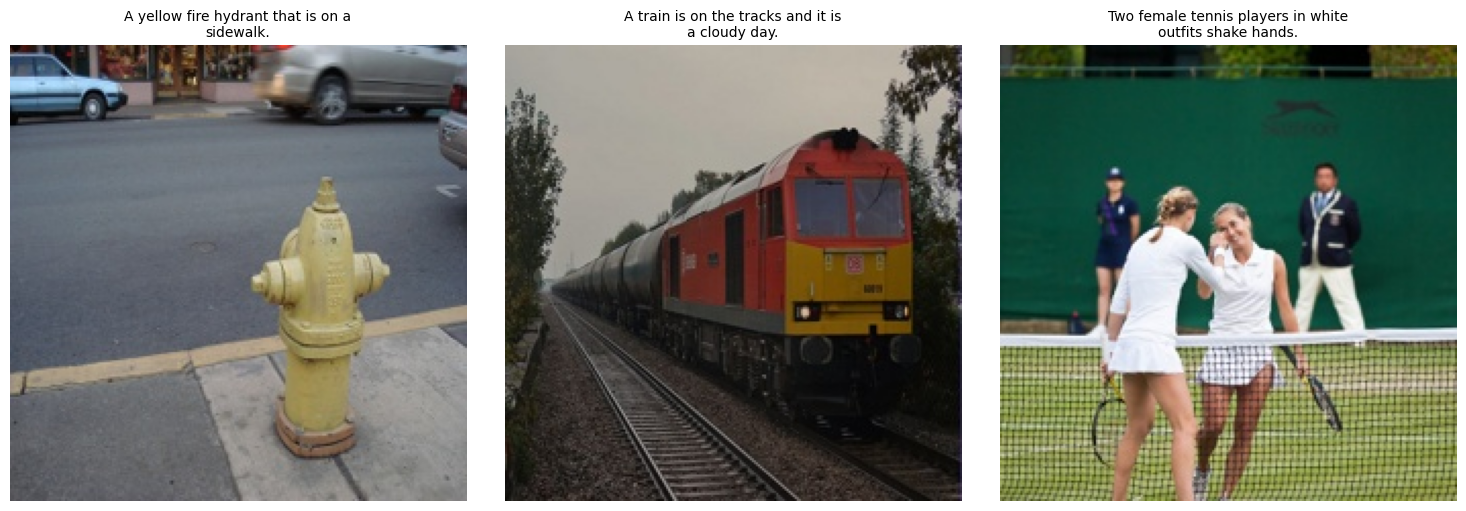

In [9]:
# Viewing Images from the Colab server

import matplotlib.pyplot as plt, textwrap
from PIL import Image

samples = train_data.sample(3)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (_, row) in zip(axes, samples.iterrows()):
    ax.imshow(Image.open(row["Img_Path"]).convert("RGB"))
    ax.set_title("\n".join(textwrap.wrap(row["Caption"], 35)), fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Dataset and DataLoader class

In [10]:
# Creating Dataset Class
# Dataset: one random caption per image per epoch

import random

class coco_dataset(Dataset):
    def __init__(self, data):
        super().__init__()

        groups = data.groupby("Img_Path")["Caption"].apply(list)    # image -> its ~5 captions
        self.paths    = groups.index.tolist()
        self.captions = groups.tolist()
        self.transformation = transforms.ToTensor()

    def __len__(self):

        return len(self.paths)

    def __getitem__(self, index):

        img = Image.open(self.paths[index]).convert("RGB")           # Grayscale images come as 2D [H, W] .convert() automatically makes them 
                                                                     # 3-channel [H, W, 3]
        return self.transformation(img), random.choice(self.captions[index])   # new caption each epoch

In [11]:
# Creating Dataset And DataLoader Object

Batch_Size = 64

train_dataset = coco_dataset(train_data)

train_loader = DataLoader(train_dataset, batch_size = Batch_Size, shuffle = True, drop_last = True, num_workers = 2, pin_memory = True, 
                          persistent_workers = True, prefetch_factor = 4)

# Image Encoder - ViT

In [12]:
# 1 Image Tensor - [16, 3, 224, 224]: We devide (224, 224) image --> into (16, 16) patch. 
# Total no. of patches formed in Image grid: Image size (224x224) / Patch size (16x16) = (14x14),
# And the total number of 16x16 patches = 14x14 = 196.
# We will take the Embedding dimesion = 768.

patch_size = 16
num_patches = 196
emd_dim = 768

In [13]:
# Patch Embedding + Linear Projection + Flattening


class patch_embed(nn.Module):

    def __init__(self):
        super().__init__()
        
        self.conv_patching = nn.Conv2d(in_channels = 3, out_channels = emd_dim, kernel_size = patch_size, stride = patch_size)

    def forward(self, in_tensor):                                           # in_tensor = [16, 3, 224, 224] (Image)
        
        patch_emd = self.conv_patching(in_tensor)                           # [16, 3, 224, 224] --> [16, 768, 14, 14]

        patch_emd = patch_emd.flatten(start_dim = 2, end_dim = 3)           # [16, 768, 14, 14] --> [16, 768, 196]

        patch_emd = patch_emd.permute(0, 2, 1)                              # [16, 768, 196] --> [16, 196, 768]

        return patch_emd                                                    # [16, 196, 768]  (196 vectors of 768-dim of 16 images)


# To be precise, a tensor shape of [16, 196, 768] represents:
# • 16 images in the current batch.
# • 196 is the number of tokens (or patches) per image (14 × 14 = 196).
# • 768 is the size (or dimensionality) of each token.

In [14]:
# Self Attention

class self_attention(nn.Module):

    def __init__(self):
        super().__init__()

        self.q = nn.Linear(emd_dim, emd_dim)
        self.k = nn.Linear(emd_dim, emd_dim)
        self.v = nn.Linear(emd_dim, emd_dim)

        self.softmax = nn.Softmax(dim = -1)

        self.proj = nn.Linear(emd_dim, emd_dim)

    def forward(self, x):                          # x --> Input feature map [16, 197, 768] - 197: 196 + 1 (CLS token)
        
        q = self.q(x)
        k = self.k(x)
        v = self.v(x)

        attn = q @ k.permute(0, 2, 1)             # Q [16, 197, 768] dot K_transpose [16, 768, 197] = [16, 197, 197]
        attn = attn / emd_dim ** 0.5
        attn = self.softmax(attn)                 # Softmax on tokens --> dim = -1; tensor[2] = [197]
        attn = attn @ v                           # [16, 197, 197] dot V [16, 197, 768] = [16, 197, 768]

        attn = self.proj(attn)

        return attn

In [15]:
# Multi-Head attention

class multi_attention(nn.Module):
    def __init__(self, num_heads):
        super().__init__()

        self.head = nn.ModuleList([self_attention() for _ in range(num_heads)])

        self.proj = nn.Linear(emd_dim * num_heads, emd_dim)

    def forward(self, x):                                  # x: [16, 197, 768]

        out = [head(x) for head in self.head]              # list of num_heads tensors, each [16, 197, 768]

        out = torch.cat(out, dim = -1)                     # [16, 197, 768 * num_heads]   (i.e: 12 heads → [16, 197, 9216])
        
        out = self.proj(out)                               # i.e: for 12 heads- [16, 197, 9216] → [16, 197, 768]

        return out

In [16]:
# Transformer Encoder block

class Transformer_Encoder(nn.Module):

    def __init__(self, num_heads):
        super().__init__()

        self.norm1 = nn.LayerNorm(emd_dim)                        # normalizes over the last dim (768)

        self.mha = multi_attention(num_heads)

        self.norm2 = nn.LayerNorm(emd_dim)

        self.mlp = nn.Sequential(nn.Linear(emd_dim, emd_dim * 4),
                                 nn.GELU(),
                                 nn.Linear(emd_dim * 4, emd_dim))

    def forward(self, x):                      # x: [16, 197, 768]

        # Normalization
        out = self.norm1(x)                    # [16, 197, 768] → [16, 197, 768]  (values normalized per token, shape same)

        # Multi-Head attention
        out = self.mha(out)                     # [16, 197, 768] → [16, 197, 768]
                                                # inside: each head [16,197,768] → cat [16,197,768*num_heads] → proj → [16,197,768]

        # Residual connection
        out = out + x                           # [16, 197, 768] + [16, 197, 768] → [16, 197, 768]   (residual 1, adds ORIGINAL x)
        res_connection = out                    # [16, 197, 768]  (saved for residual 2)

        # Normalization
        out = self.norm2(out)                   # [16, 197, 768] → [16, 197, 768]

        # MLP
        out = self.mlp(out)                     # [16, 197, 768]
                                                #   Linear 1 → [16, 197, 3072]
                                                #   GELU     → [16, 197, 3072]
                                                #   Linear 2 → [16, 197, 768]

        # Residual connection
        out = out + res_connection              # [16, 197, 768] + [16, 197, 768] → [16, 197, 768]   (residual 2)

        return out                              # [16, 197, 768]

In [17]:
# ViT class

class vit(nn.Module):

    def __init__(self, num_heads, num_transformer_block):          # num_heads → number of attention heads inside EACH transformer block.
        super().__init__()                                         # num_transformer_block → depth of the ViT: how many Transformer_Encoder 
                                                                   # blocks are stacked in sequence.

        

        self.patch_embedding = patch_embed()

        self.cls_token = nn.Parameter(torch.randn(1, 1, emd_dim))    # This creates one CLS token for each image in the batch: [1, 1, embed_dim]

        self.pos_encod_vector = nn.Parameter(torch.randn(1, num_patches + 1, emd_dim))    # one vector per position: [1, 197, 768]

        self.transformer_block = nn.Sequential(*[Transformer_Encoder(num_heads) for _ in range(num_transformer_block)])

        self.norm = nn.LayerNorm(emd_dim)




    def forward(self, x):                                        # (Image) x: [B, 3, 224, 224] 

        # Patch Embedding + Linear Projection + Flattening
        x = self.patch_embedding(x)                              # [B, 3, 224, 224] → [B, 196, 768]

        # CLS token
        B = x.shape[0]                                           # B → Batch_size, not using Batch_size = 16, cause final batch might not be 16
        cls_token = self.cls_token.expand(B, -1, -1)             # [1, 1, 768] → [B, 1, 768]  
        x = torch.cat([cls_token, x], dim = 1)                   # [B, 1, 768] + [B, 196, 768] → [B, 197, 768]   (Concatenating such 
                                                                 # that CLS is first, at ind 0, if did[x, cls_token] then cls is at last index)
        
        # Positional Encoding + Patch vector
        pos_encoding_vec = self.pos_encod_vector
        x = x + pos_encoding_vec                                 # [B, 197, 768] + [1, 197, 768] → [B, 197, 768]  (broadcast over batch)

        # Transformer Encoder block
        x = self.transformer_block(x)                            # [B, 197, 768] → [B, 197, 768]   (shape unchanged through every block)

        # Normalising
        x = self.norm(x)                                         # Normalizing tensor so that CLS vector going into the CLIP projection does not have large, unnormalized values, Cause it is comming straight out of the residual connection.

        # Extracting CLS token
        cls = x[:, 0]                                            # [B, 197, 768] → [B, 768] 

        return cls                                               # [B, 768]
    

# Text Encoder

In [18]:
# To get rid of all that unwanted clutter after downloading Text encoder model from Hugging face, we need to suppress three separate things: Google Colab token timeouts,
# Hugging Face network logs/warnings, and broken Jupyter progress bars (ipywidgets)

import warnings
import logging

# Block Colab server from trying to fetch a secret token and timing out
os.environ["HF_TOKEN"] = ""

# Silence Hugging Face Hub and Transformers logging warnings
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

from transformers.utils import logging as tf_logging
tf_logging.set_verbosity_error()

# 3. Ignore Python UserWarnings
warnings.filterwarnings("ignore", category=UserWarning)

In [19]:
# Downloading Pretrained Text Encoder

from transformers import CLIPTokenizer, CLIPTextModel

model_name = 'openai/clip-vit-base-patch32'

tokenizer = CLIPTokenizer.from_pretrained(model_name)

text_encoder = CLIPTextModel.from_pretrained(model_name)        # In this Text_encoder the dropout is already 0.0 while training

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

# CLIP Model

In [20]:
# CLIP model

class clip(nn.Module):
    def __init__(self):      
        super().__init__()

        # ---------------------Image Tower-----------------------

        # ViT
        self.vit_model = vit(num_heads = 4, num_transformer_block = 6)

        # Image Linear Projection
        self.img_proj = nn.Linear(768, 512, bias = False)


        # --------------------Text Tower--------------------------

        # Caption Linear Projection
        self.cap_proj = nn.Linear(512, 512, bias = False)

        # Tokenizer
        self.tokenizer = tokenizer

        # Text Encoder
        self.text_encoder = text_encoder

        for params in text_encoder.parameters():
            params.requires_grad = False
            
        self.text_encoder.eval()                                        

       # ---------------------Logit-------------------------------
        
        starting_logit = torch.tensor(math.log(1/0.07))                 # [log(14.28)]  -- just a starting initial value for logit
        self.logit_scale = nn.Parameter(starting_logit)


    def forward(self, img, caption):                                    # img: [B, 3, 224, 224]  &  caption: list of B strings

        # ---------------------Image Tower-----------------------                

        # ViT
        img_embedding = self.vit_model(img)                             # [B, 3, 224, 224] → [B, 768]

        # Linear Proj
        img_embedding = self.img_proj(img_embedding)                    # [B, 768] → [B, 512]

        # L2 Normalize
        img_embedding = nn.functional.normalize(img_embedding, p = 2, dim = -1)    # [B, 512] → [B, 512]  (each row's L2 norm = 1)


        # --------------------Text Tower--------------------------

        # Tokenizer
        token = tokenizer(
            caption,
            padding = True,
            truncation = True,
            return_tensors = "pt"
        )                                                              # list of B strings → input_ids, attention_mask: [B, L]  (L ≈ 15)
        token = {k: v.to(device) for k, v in token.items()}            # Moving tokens on device

        # Text Encoder (FROZEN)
        with torch.no_grad():                                          # frozen: no gradient bookkeeping
            out = self.text_encoder(**token)                           # Here 'out' is a special structured container designed to hold the raw results of a neural network
                                                                       # forward pass. Under the hood, the actual data points inside this container are PyTorch Tensors.
            cap_embedding = out.pooler_output                          # Taking tensor out of the container 'out' -> [B, 512]

        # Linear Proj
        cap_embedding = self.cap_proj(cap_embedding)                   # [B, 512] → [B, 512]

        # L2 Normalize
        cap_embedding = nn.functional.normalize(cap_embedding, p = 2, dim = -1)    # [B, 512] → [B, 512]  (L2 norm = 1)


        # ------------------------Similarity score and Logits------------------------------------

        cap_embedding = cap_embedding.T                                # [512, B] 

        similarity_score = img_embedding @ cap_embedding               # [B, 512] @ [512, B] → [B, B]    cosine similarities in range: [-1, 1]

        logits = similarity_score * self.logit_scale.exp()             # [B, B] * scale_value → [B, B]   



        return logits

In [21]:
# Contrastive Loss (InfoNCE)

def loss_fun(logits):                                           # logits: [B, B]

    B = logits.shape[0]

    label = torch.arange(B, device=logits.device)               # [B]   [0, 1, ..., B-1]  (correct column for each row)

    loss_i2t = nn.functional.cross_entropy(logits, label)       # [B, B] + [B] → scalar   rows:    image → caption
    loss_t2i = nn.functional.cross_entropy(logits.T, label)     # [B, B] + [B] → scalar   columns: caption → image

    loss = (loss_i2t + loss_t2i) / 2

    return loss

# Initializing CLIP model, and starting training


In [22]:
# Initializing the CLIP model, and Optimizer

model = clip().to(device)

optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr = 3e-4, fused = True)
# [..] tells the optimizer to only update weights where requires_grad=True
# Instead of performing the math for updating weights step-by-step (which involves launching multiple separate operations on the GPU), 
# fused=True combines (fuses) the entire optimization step into a single GPU operation.

torch.backends.cudnn.benchmark = True
# This activates an internal auto-tuner in PyTorch’s built-in CUDA Deep Neural Network library (cuDNN). When you set this to True, cuDNN will 
# test several different mathematical algorithms to find the absolute fastest one for your specific hardware and neural network architecture.

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
# Training CLIP
# ===== Training: fp16 mixed precision + progress bar + checkpoint every epoch =====
# T4 GPUs support fp16 (not bf16), so GradScaler is needed.
# Loss is accumulated on the GPU (no .item() sync every step).


scaler = torch.amp.GradScaler("cuda")

Epoch = 5

model.train()

epoch_loss_val = []

for epoch in range(Epoch):
    
    total_epoch_loss = torch.zeros((), device=device)

    for img, cap in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{Epoch}"):       # img: [B, 3, 224, 224]  &  caps stays a list of B strings
        
        img = img.to(device, non_blocking=True)                             

        with torch.autocast("cuda", dtype=torch.float16):
            # CLIP model's forward pass
            logits = model(img, cap)
            # Loss function
            loss = loss_fun(logits)

        # Backpropagation
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_epoch_loss += loss.detach()
        epoch_loss_val.append(total_epoch_loss)

    print(f"Epoch [{epoch + 1}/{Epoch}]: Loss: {total_epoch_loss.item() / len(train_loader):.5f}")
    torch.save(model.state_dict(), "/content/clip_last.pt")                                # survives a crash, not a runtime reset

Epoch 1/5:   0%|          | 0/1848 [00:00<?, ?it/s]

Epoch [1/5]: Loss: 3.70152


Epoch 2/5:   0%|          | 0/1848 [00:00<?, ?it/s]